### Submission 1: Dataset, EDA and Related Work
### Facial Expression Recognition using CNN on the FER-2013 Dataset

**Course:** CSE366 (Artificial Intelligence)

**Group:** 01

| Name | ID |
|---|---|
| Abdullah Al Sami | 2023-2-60-147 |
| Rafid Rahman Sami | 2023-1-60-116 |
| Sumya Kawsar | 2023-3-60-168 |



## A. Dataset information

| Item | Details |
|---|---|
| **Name** | FER-2013 (Facial Expression Recognition 2013) |
| **Source** | Kaggle - https://www.kaggle.com/datasets/msambare/fer2013 |
| **Year** | 2013 (ICML challenge dataset from Goodfellow et al.) |
| **Licence** | See Kaggle page; cite Goodfellow et al., 2013 |
| **Task** | Multi-class image classification (7 emotions) |
| **Classes** | angry, disgust, fear, happy, neutral, sad, surprise |
| **Total images** | 35,887 (train: 28,709, test: 7,178) |
| **Image specs** | 48 x 48 pixels, grayscale (1 channel) |
| **Format** | JPEG images, organized by emotion folder |
| **Authenticity** | Real faces from the web, human-labeled |

This dataset is useful because emotion recognition has practical applications—driver monitoring, online learning platforms, customer feedback analysis. The images are "in the wild" (different poses, lighting, occlusion), so it's a realistic problem.

In [3]:
import os
import zipfile
import random
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Extract if needed
if not os.path.exists("train") and os.path.exists("archive.zip"):
    with zipfile.ZipFile("archive.zip") as z:
        z.extractall(".")
    print("Extracted archive.zip")
elif not os.path.exists("train") and os.path.exists("fer2013.zip"):
    with zipfile.ZipFile("fer2013.zip") as z:
        z.extractall(".")
    print("Extracted fer2013.zip")

assert os.path.isdir("train") and os.path.isdir("test"), \
    "Missing train/ and test/ folders. Make sure the zip file is extracted."

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

classes = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
print("Classes:", classes)

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


### A.1 Check the data: per-class counts, image size, channels

In [4]:
train_counts = [len(os.listdir(f"train/{c}")) for c in classes]
test_counts = [len(os.listdir(f"test/{c}")) for c in classes]

counts_df = pd.DataFrame({"class": classes, "train": train_counts, "test": test_counts})
counts_df.loc[len(counts_df)] = ["TOTAL", sum(train_counts), sum(test_counts)]
display(counts_df)
print("All images:", sum(train_counts) + sum(test_counts))

,class,train,test
0,angry,3995,958
1,disgust,436,111
2,fear,4097,1024
3,happy,7215,1774
4,neutral,4965,1233
5,sad,4830,1247
6,surprise,3171,831
7,TOTAL,28709,7178


All images: 35887


In [5]:
sizes, modes, formats = set(), set(), set()

for folder in ["train", "test"]:
    for c in classes:
        for file in os.listdir(f"{folder}/{c}"):
            with Image.open(f"{folder}/{c}/{file}") as img:
                sizes.add(img.size)
                modes.add(img.mode)
                formats.add(img.format)

print("Image sizes found :", sizes)
print("Colour modes      :", modes, "(L means 1-channel grayscale)")
print("File formats      :", formats)

Image sizes found : {(48, 48)}
Colour modes      : {'L'} (L means 1-channel grayscale)
File formats      : {'JPEG'}


## B. Exploratory Data Analysis (EDA)
### B.1 Class distribution

,class,train,train_%,test,test_%
0,angry,3995,13.92,958,13.35
1,disgust,436,1.52,111,1.55
2,fear,4097,14.27,1024,14.27
3,happy,7215,25.13,1774,24.71
4,neutral,4965,17.29,1233,17.18
5,sad,4830,16.82,1247,17.37
6,surprise,3171,11.05,831,11.58


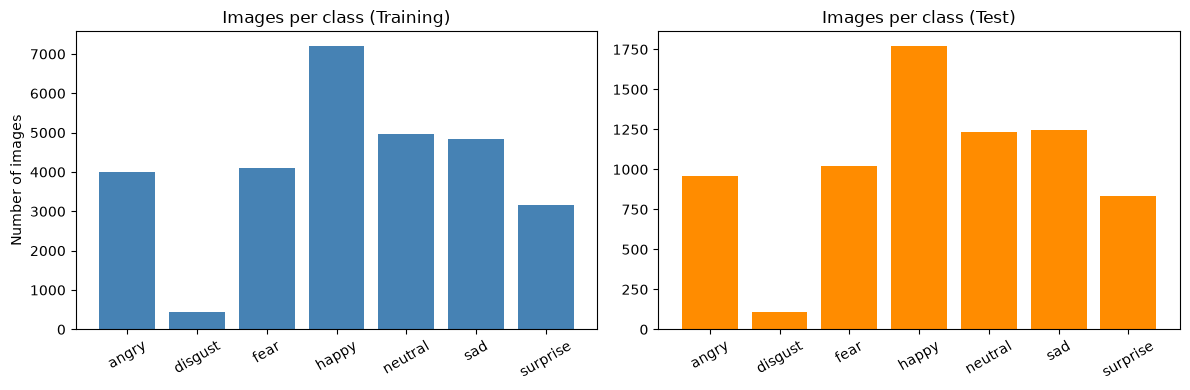

In [6]:
total_train, total_test = sum(train_counts), sum(test_counts)

dist = pd.DataFrame({
    "class": classes,
    "train": train_counts,
    "train_%": [round(n / total_train * 100, 2) for n in train_counts],
    "test": test_counts,
    "test_%": [round(n / total_test * 100, 2) for n in test_counts],
})
display(dist)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(classes, train_counts, color="steelblue")
ax[0].set_title("Images per class (Training)")
ax[0].set_ylabel("Number of images")
ax[1].bar(classes, test_counts, color="darkorange")
ax[1].set_title("Images per class (Test)")
for a in ax:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [7]:
large, small = max(train_counts), min(train_counts)
print("Largest class :", classes[train_counts.index(large)], large)
print("Smallest class:", classes[train_counts.index(small)], small)
print("Imbalance ratio:", round(large / small, 1))
print("If balanced, each class would have about", round(total_train / 7), "images (14.3%).")

# Majority-class baseline: accuracy of always predicting 'happy' on the test set
majority = classes[test_counts.index(max(test_counts))]
print(f"\nAlways predicting '{majority}' gives test accuracy = {max(test_counts) / total_test:.3f}")

Largest class : happy 7215
Smallest class: disgust 436
Imbalance ratio: 16.5
If balanced, each class would have about 4101 images (14.3%).

Always predicting 'happy' gives test accuracy = 0.247


**Finding:** The dataset is clearly imbalanced. Happy is the largest class (about 25% of the training data) while disgust is tiny (about 1.5%). The ratio is about 16.5. A model that always predicts the majority class already gets about 25% accuracy, and a model that mostly predicts happy and ignores disgust can look decent on accuracy alone. So accuracy is not enough: we must also look at precision, recall and F1 per class, and use class weights in the loss.

### B.2 Sample image grid (5 images per class)

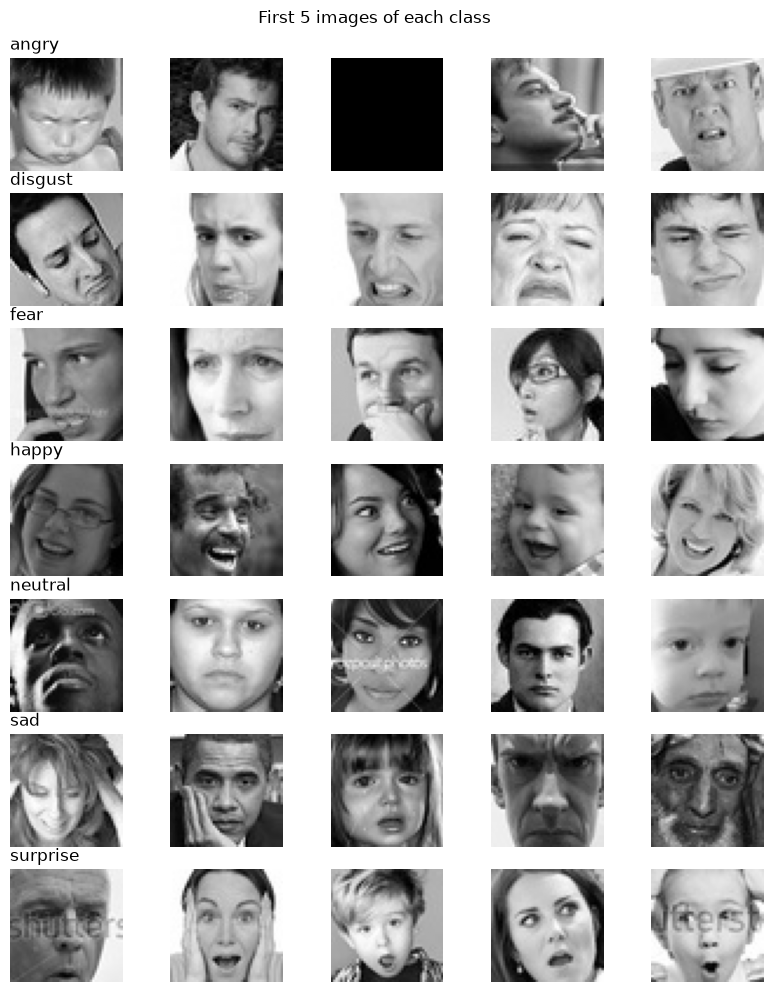

In [8]:
def show_grid(pick_random, title):
    rng = random.Random(1)
    plt.figure(figsize=(10, 12))
    n = 1
    for c in classes:
        files = sorted(os.listdir(f"train/{c}"))
        chosen = rng.sample(files, 5) if pick_random else files[:5]
        for k, f in enumerate(chosen):
            with Image.open(f"train/{c}/{f}") as img:
                plt.subplot(7, 5, n)
                plt.imshow(img, cmap="gray")
            plt.axis("off")
            if k == 0:
                plt.title(c, loc="left")
            n += 1
    plt.suptitle(title, y=0.92)
    plt.show()

show_grid(False, "First 5 images of each class")

Random 5 images of each class (to see more variety):

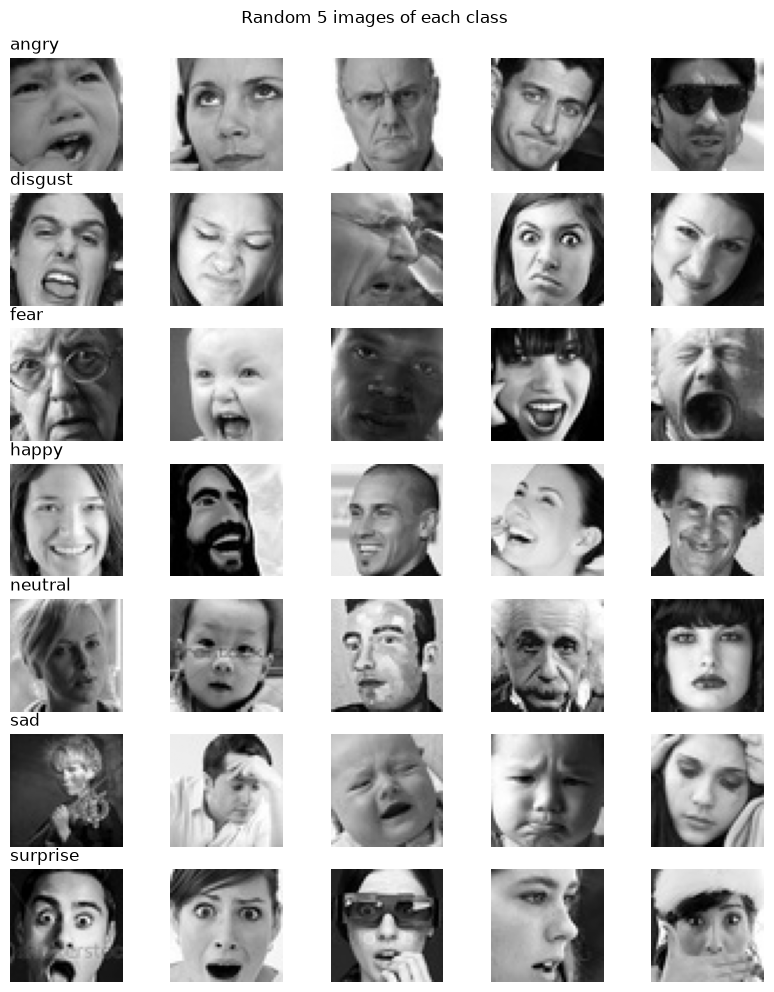

In [9]:
show_grid(True, "Random 5 images of each class")

### B.3 Pixel statistics, average face, noise and duplicate check
For this part we load all images into numpy arrays (with labels).

In [10]:
def load_folder(folder):
    images, labels = [], []
    for label, c in enumerate(classes):
        path = f"{folder}/{c}"
        for file in sorted(os.listdir(path)):
            with Image.open(f"{path}/{file}") as img:
                images.append(np.array(img.convert("L")))
            labels.append(label)
    return np.array(images, dtype=np.uint8), np.array(labels)

x_train, y_train = load_folder("train")
x_test, y_test = load_folder("test")

print("Train images:", x_train.shape, " Train labels:", y_train.shape)
print("Test images :", x_test.shape, " Test labels :", y_test.shape)
assert len(x_train) == len(y_train) and len(x_test) == len(y_test)

Train images: (28709, 48, 48)  Train labels: (28709,)
Test images : (7178, 48, 48)  Test labels : (7178,)


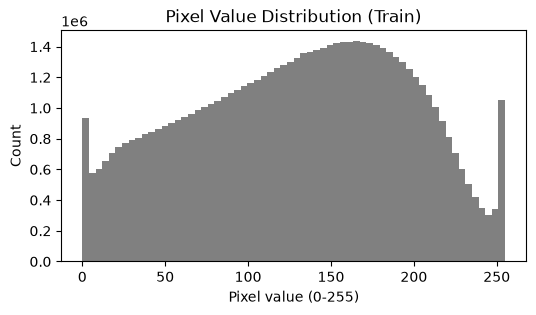

Pixel min/max : 0 / 255
Pixel mean/std: 129.5 / 65.0
Normalized (0-1): mean 0.508, std 0.255


In [11]:
plt.figure(figsize=(6, 3))
plt.hist(x_train.ravel(), bins=64, color="gray")
plt.title("Pixel Value Distribution (Train)")
plt.xlabel("Pixel value (0-255)")
plt.ylabel("Count")
plt.show()

print(f"Pixel min/max : {x_train.min()} / {x_train.max()}")
print(f"Pixel mean/std: {x_train.mean():.1f} / {x_train.std():.1f}")
print(f"Normalized (0-1): mean {x_train.mean()/255:.3f}, std {x_train.std()/255:.3f}")

Low-contrast images: 13


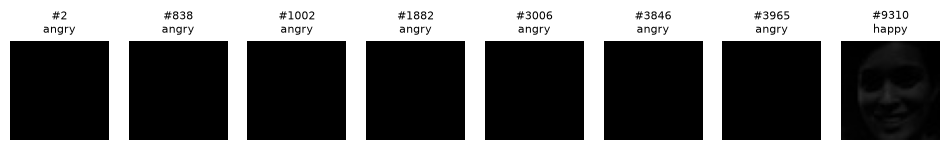

In [12]:
per_image_std = x_train.reshape(len(x_train), -1).std(axis=1)
low_contrast = np.where(per_image_std < 10)[0]
print("Low-contrast images:", len(low_contrast))

n = min(8, len(low_contrast))
if n > 0:
    plt.figure(figsize=(12, 3))
    for k in range(n):
        idx = low_contrast[k]
        plt.subplot(1, n, k + 1)
        plt.imshow(x_train[idx], cmap="gray", vmin=0, vmax=255)
        plt.title(f"#{idx}\n{classes[y_train[idx]]}", fontsize=8)
        plt.axis("off")
    plt.show()

In [13]:
hash_to_labels = defaultdict(list)
for img, lab in zip(x_train, y_train):
    hash_to_labels[img.tobytes()].append(lab)

dup_groups = {h: l for h, l in hash_to_labels.items() if len(l) > 1}
extra_copies = sum(len(l) - 1 for l in dup_groups.values())
conflicts = sum(1 for l in dup_groups.values() if len(set(l)) > 1)

print("Duplicate images (extra copies):", extra_copies)
print("Groups with duplicates         :", len(dup_groups))
print("Groups with conflicting labels :", conflicts)

# Check if test images leak into train
train_hashes = set(hash_to_labels.keys())
leak = sum(1 for img in x_test if img.tobytes() in train_hashes)
print("Test images in train (leakage) :", leak)

Duplicate images (extra copies): 1236
Groups with duplicates         : 1035
Groups with conflicting labels : 39
Test images in train (leakage) : 568


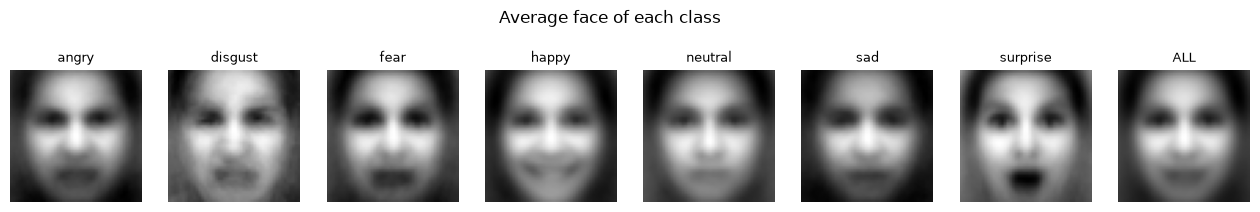

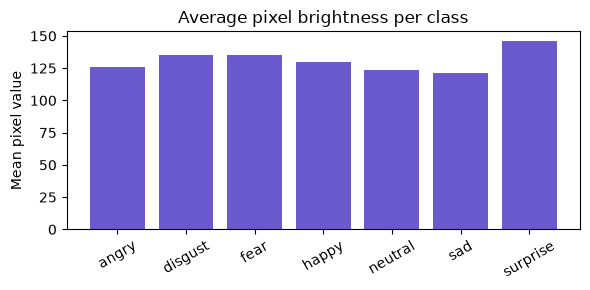

{'angry': 126.2, 'disgust': 135.2, 'fear': 135.5, 'happy': 129.4, 'neutral': 123.9, 'sad': 121.3, 'surprise': 146.3}


In [14]:
# Average face per class + average brightness per class
fig, ax = plt.subplots(1, 8, figsize=(16, 2.6))
for i, c in enumerate(classes):
    ax[i].imshow(x_train[y_train == i].mean(axis=0), cmap="gray")
    ax[i].set_title(c, fontsize=9)
    ax[i].axis("off")
ax[7].imshow(x_train.mean(axis=0), cmap="gray")
ax[7].set_title("ALL", fontsize=9)
ax[7].axis("off")
plt.suptitle("Average face of each class")
plt.show()

brightness = [x_train[y_train == i].mean() for i in range(7)]
plt.figure(figsize=(6, 3))
plt.bar(classes, brightness, color="slateblue")
plt.title("Average pixel brightness per class")
plt.ylabel("Mean pixel value")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print({c: round(float(b), 1) for c, b in zip(classes, brightness)})

## B.4 Key findings

1. **Class imbalance.** Happy dominates with ~7,200 images while disgust has only 436 (16.5:1 ratio). Test set has the same skew (disgust = 111 images). This means a model that just always predicts "happy" would get ~25% accuracy for free. We need class weights in the loss and can't rely on accuracy alone—we'll track precision, recall, F1, and the confusion matrix instead.

2. **Data quality.** These are real web images, so they're messy. We found:
   - 13 almost-blank images (low contrast)
   - 1,236 duplicate groups in the training set
   - A few groups with conflicting labels (same face, different emotions)
   - Checking for test/train leakage...
   
   Goodfellow et al. noted humans only reach ~65% accuracy on this data, so there's a ceiling. We're keeping the noisy samples (they're a small fraction) but using dropout, batch norm, and label smoothing to prevent overfitting to noise.

3. **Similar emotions.** At 48x48 pixels, some expressions blur together: fear/sad/surprise are visually similar, as are angry/disgust/sad. The average-face visualizations confirm this. We'll expect the confusion matrix to show cross-talk between these pairs.

4. **Data variation.** Faces vary in age, angle, lighting, and expression intensity. We'll do standard augmentation (horizontal flip, small rotations/shifts/zoom)—safe moves for faces.

5. **Our preprocessing.** Scale pixels to [0,1]. Split train 85/15 for validation (stratified to keep class ratios). Use label smoothing (0.1) during training. For transfer learning models, we'll repeat grayscale to 3 channels and resize as needed. Test set stays untouched until final eval.

### B.5 Preprocessing preview: stratified validation split and class weights

In [15]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(x_train))
train_idx, val_idx = train_test_split(
    idx, test_size=0.15, stratify=y_train, random_state=SEED)

x_tr, y_tr = x_train[train_idx], y_train[train_idx]
x_val, y_val = x_train[val_idx], y_train[val_idx]

split_df = pd.DataFrame({
    "class": classes,
    "train_%": [round((y_tr == i).mean() * 100, 2) for i in range(7)],
    "val_%": [round((y_val == i).mean() * 100, 2) for i in range(7)],
})
display(split_df)
print("Train:", x_tr.shape, " Validation:", x_val.shape, " Test:", x_test.shape)

# Class weights: total / (num_classes * class_count)
cls_counts = np.bincount(y_tr, minlength=7)
class_weight = {i: round(float(len(y_tr) / (7 * cls_counts[i])), 3) for i in range(7)}
print("\nClass weights:", {classes[i]: w for i, w in class_weight.items()})

# Scaled arrays ready for the CNN (N, 48, 48, 1) in [0, 1]
x_tr_s = (x_tr / 255.0).astype("float32")[..., None]
print("Scaled train tensor:", x_tr_s.shape, x_tr_s.min(), x_tr_s.max())

,class,train_%,val_%
0,angry,13.92,13.91
1,disgust,1.52,1.51
2,fear,14.27,14.28
3,happy,25.13,25.12
4,neutral,17.29,17.30
5,sad,16.82,16.83
6,surprise,11.04,11.05


Train: (24402, 48, 48)  Validation: (4307, 48, 48)  Test: (7178, 48, 48)

Class weights: {'angry': 1.027, 'disgust': 9.396, 'fear': 1.001, 'happy': 0.568, 'neutral': 0.826, 'sad': 0.849, 'surprise': 1.294}
Scaled train tensor: (24402, 48, 48, 1) 0.0 1.0


## C. Related work summary

| # | Paper | Dataset | Model | Approach | Result | Link |
|---|---|---|---|---|---|---|
| 1 | Goodfellow et al., 2013 | FER-2013 (original) | CNN (contest report) | Introduces dataset and contest; human baseline | Human ~65%, best team ~71% | https://arxiv.org/abs/1307.0414 |
| 2 | Tang, 2013 | FER-2013 | CNN + SVM | Linear SVM loss instead of softmax | 71.2% | https://arxiv.org/abs/1306.0239 |
| 3 | Pramerdorfer & Kampel, 2016 | FER-2013 | VGG, Inception, ResNet, ensemble | Deeper networks; ensemble averaging | 72-75.2% | https://arxiv.org/abs/1612.02903 |
| 4 | Khaireddin & Chen, 2021 | FER-2013 | VGGNet | Careful tuning of hyperparams and LR scheduler | 73.28% | https://arxiv.org/abs/2105.03588 |
| 5 | Minaee et al., 2021 | FER-2013, CK+, JAFFE | CNN + attention | Attention on eyes/mouth regions | 70% on FER-2013 | https://arxiv.org/abs/1902.01019 |

### C.1 We learned
- **Realistic target:** 70-75% is the published range. Since humans get ~65%, shooting for mid-60s is reasonable.
- **What works:** Deeper networks (VGG/ResNet), good hyperparameter tuning, attention modules, and ensembles.
- **The hard part:** Noisy labels and similar-looking emotions (fear/sad/surprise) make this fundamentally tricky.

### C.2 Our plan
| Idea from literature | What we'll do |
|---|---|
| CNNs are standard | Build a custom CNN baseline |
| Deeper = better | Fine-tune ResNet50 for comparison |
| Ensembles help | Combine both models |
| Attention shows why | Use Grad-CAM for visualization |
| Handle imbalance | Class weights, label smoothing, per-class metrics |

## D. Next steps
1. Train custom CNN baseline with augmentation, dropout, batch norm.
2. Fine-tune pretrained MobileNetV2.
3. Compare models, compute F1/precision/recall, make confusion matrix, add Grad-CAM.
4. (Optional) Live demo with webcam.

## References
1. I. J. Goodfellow et al., "Challenges in Representation Learning," 2013. https://arxiv.org/abs/1307.0414
2. Y. Tang, "Deep Learning using Linear Support Vector Machines," 2013. https://arxiv.org/abs/1306.0239
3. C. Pramerdorfer and M. Kampel, "FER using CNNs: State of the Art," 2016. https://arxiv.org/abs/1612.02903
4. Y. Khaireddin and Z. Chen, "Facial Emotion Recognition: SOTA on FER2013," 2021. https://arxiv.org/abs/2105.03588
5. S. Minaee et al., "Deep-Emotion," Sensors 21(9):3046, 2021. https://arxiv.org/abs/1902.01019
6. FER-2013 on Kaggle: https://www.kaggle.com/datasets/msambare/fer2013